# Iris Flower Classification

**Problem:** Given four measurements of an iris flower (sepal/petal length and width), predict its species — *setosa*, *versicolor* or *virginica*.

**Dataset:** the classic Fisher Iris dataset (built into scikit-learn) — 150 flowers, 4 features, 3 species.

**Approach:** compare Logistic Regression and Random Forest on a held-out test set.

In [1]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

iris = load_iris()
X, y = iris.data, iris.target
print("Samples:", X.shape, "| Classes:", list(iris.target_names))
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
print("Train:", X_tr.shape, "| Test:", X_te.shape)

Samples: (150, 4) | Classes: [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]
Train: (112, 4) | Test: (38, 4)


Logistic Regression accuracy: 0.9474
Random Forest accuracy: 0.8947
              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        12
  versicolor      0.800     0.923     0.857        13
   virginica      0.909     0.769     0.833        13

    accuracy                          0.895        38
   macro avg      0.903     0.897     0.897        38
weighted avg      0.900     0.895     0.894        38



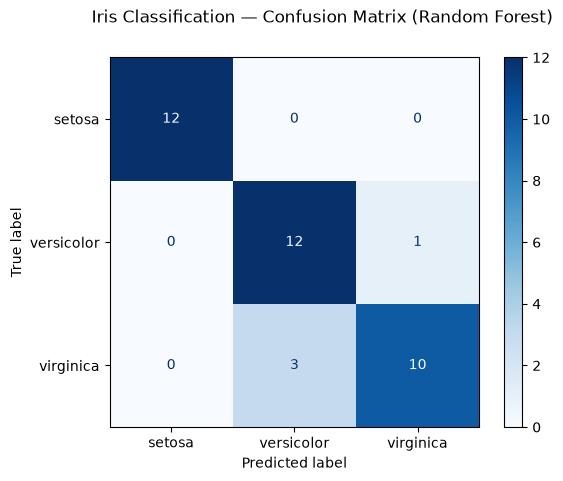

In [2]:
lr = LogisticRegression(max_iter=1000).fit(X_tr, y_tr)
rf = RandomForestClassifier(n_estimators=200, random_state=42).fit(X_tr, y_tr)
for name, m in [("Logistic Regression", lr), ("Random Forest", rf)]:
    print(name, "accuracy:", round(accuracy_score(y_te, m.predict(X_te)), 4))
print(classification_report(y_te, rf.predict(X_te), target_names=iris.target_names, digits=3))
disp = ConfusionMatrixDisplay.from_predictions(y_te, rf.predict(X_te), display_labels=iris.target_names, cmap="Blues")
disp.figure_.suptitle("Iris Classification — Confusion Matrix (Random Forest)")
disp.figure_.savefig("confusion_matrix.png", dpi=110, bbox_inches="tight")

## Result
On this 38-flower test split, **Logistic Regression scored 94.7%** and **Random Forest 89.5%** (executed output above). Iris is the "hello world" of classification: tiny and clean, but with only 38 test flowers, one flower is worth ~2.6% — small datasets make jumpy scores.